In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.metrics import accuracy_score, roc_curve, auc
from sklearn.model_selection import KFold
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve, auc


# Load the Higgs dataset
higgs_data = fetch_openml(name='higgs', version=1, as_frame =True)
higgs_data_df = higgs_data.frame

# --- 1. DATA PREP & SCALING ---
# We fill NaNs with the mean to preserve as many collision events as possible
X = higgs_data_df.drop(columns=['class']).fillna(higgs_data_df.mean())
Y = higgs_data_df ['class'].astype(int)

feature_names = X.columns

# Dividing in 80% training and 20% test
#The training is used for the extimation
#The test is used for the accuracy and ROC
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [ ]:
#use a fixed depth of 5 to prevent overfitting on this dataset
tree_model = DecisionTreeClassifier(max_depth=20, random_state=42)
tree_model.fit(X_test, Y_test)

print("Training accuracy:", tree_model.score(X_test, Y_test))
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

Training accuracy: 0.9792452830188679
Tree depth: 20
Number of leaves: 2652


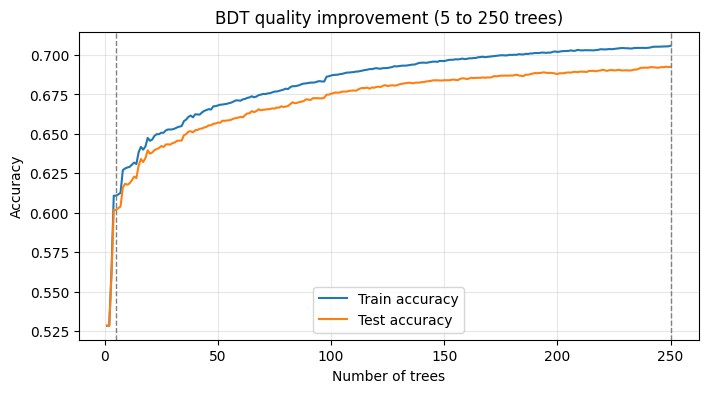

In [ ]:
trees_num = 250


# 1) Quality improvement from 5 to trees_num trees
# limit the depth to 2 to prevent overfitting and show the improvement from more trees
gbdt = GradientBoostingClassifier(
	n_estimators=trees_num, learning_rate=0.05, max_depth=2, random_state=42
)
gbdt.fit(X_train, Y_train)

train_acc = []
test_acc = []
for y_pred_tr, y_pred_te in zip(gbdt.staged_predict(X_train), gbdt.staged_predict(X_test)):
	train_acc.append(accuracy_score(Y_train, y_pred_tr))
	test_acc.append(accuracy_score(Y_test, y_pred_te))

plt.figure(figsize=(8, 4))
plt.plot(range(1, trees_num + 1), train_acc, label="Train accuracy")
plt.plot(range(1, trees_num + 1), test_acc, label="Test accuracy")
plt.axvline(5, color="gray", linestyle="--", linewidth=1)
plt.axvline(trees_num, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Number of trees")
plt.ylabel("Accuracy")
plt.title(f"BDT quality improvement (5 to {trees_num} trees)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

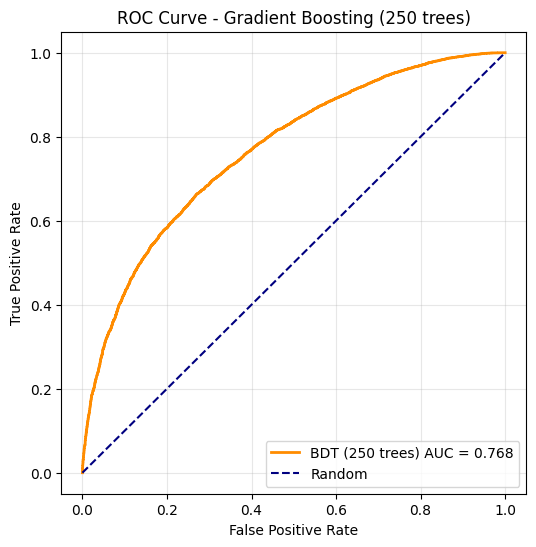

In [ ]:
# ROC on test set for the trees_num boosted model
Y_score = gbdt.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(Y_test, Y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"BDT ({trees_num} trees) AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - Gradient Boosting ({trees_num} trees)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

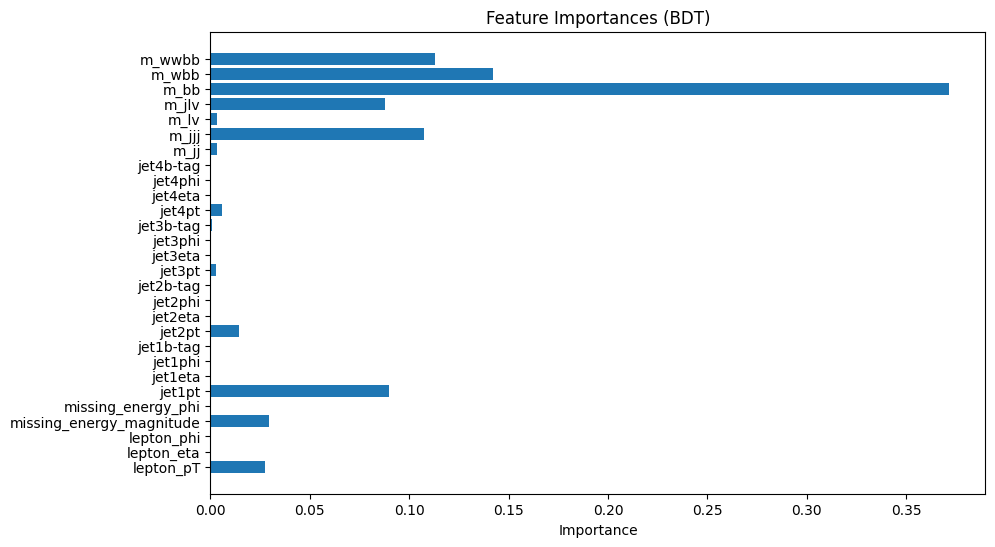

In [ ]:
# Feature importance for BDT
bdt_importances = gbdt.feature_importances_
plt.figure(figsize=(10, 6))
plt.barh(feature_names, bdt_importances)
plt.xlabel('Importance')
plt.title('Feature Importances (BDT)')
plt.show()

In [ ]:
#too long to be run


# Cost-complexity pruning: choose stopping condition (ccp_alpha) with 5-fold CV
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_test, Y_test)
ccp_alphas = np.unique(path.ccp_alphas)

# Drop the largest alpha (usually collapses to a trivial tree)
if ccp_alphas.size > 1:
	ccp_alphas = ccp_alphas[:-1]

#perform 5-fold CV for each candidate alpha
rng = np.random.RandomState(42)
indices = rng.permutation(len(Y_test))
folds = np.array_split(indices, 5)

alpha_scores = []
for alpha in ccp_alphas:
	fold_scores = []
	for i in range(5):
		val_idx = folds[i]
		train_idx = np.concatenate([folds[j] for j in range(5) if j != i])

		model = DecisionTreeClassifier(random_state=42, ccp_alpha=float(alpha))
		model.fit(X_test.iloc[train_idx], Y_test.iloc[train_idx])
		fold_scores.append(model.score(X_test.iloc[val_idx], Y_test.iloc[val_idx]))

	alpha_scores.append(np.mean(fold_scores))

best_alpha = float(ccp_alphas[int(np.argmax(alpha_scores))]) if len(alpha_scores) > 0 and len(ccp_alphas) > 0 else 0.0
tree_model = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)

print(f"Selected ccp_alpha (CV): {best_alpha:.6f}")
tree_model.fit(X_test, Y_test)

print("Training accuracy:", tree_model.score(X_test, Y_test))
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

KeyboardInterrupt: 